In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

import zipfile

with zipfile.ZipFile('/content/student+performance.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [3]:

import os

for root, dirs, files in os.walk('/content/dataset'):
    for file in files:
        print(os.path.join(root, file))


/content/dataset/student.zip
/content/dataset/.student.zip_old


In [4]:

import zipfile
import os

with zipfile.ZipFile('/content/dataset/student.zip', 'r') as z:
    z.extractall('/content/dataset/files')

for root, dirs, files in os.walk('/content/dataset/files'):
    for file in files:
        print(os.path.join(root, file))


/content/dataset/files/student.txt
/content/dataset/files/student-por.csv
/content/dataset/files/student-mat.csv
/content/dataset/files/student-merge.R


In [5]:

df = pd.read_csv('/content/dataset/files/student-mat.csv', sep=';')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Final grade (G3) summary:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


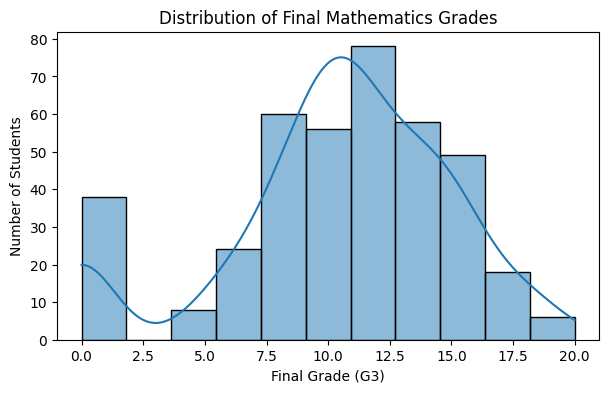

In [7]:

print("Final grade (G3) summary:")
print(df['G3'].describe())

plt.figure(figsize=(7, 4))
sns.histplot(df['G3'], bins=11, kde=True)
plt.title('Distribution of Final Mathematics Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.show()


In [8]:

# Select the target variable
y = df['G3']

# Select input features, excluding earlier grades
X = df.drop(columns=['G1', 'G2', 'G3'])

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

X.head()


Input features shape: (395, 39)
Target shape: (395,)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training input: (316, 39)
Testing input: (79, 39)
Training target: (316,)
Testing target: (79,)


In [10]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [11]:

y_pred = model.predict(X_test)

print("Actual grades:", list(y_test[:10]))
print("Predicted grades:", y_pred[:10].round(2))


Actual grades: [10, 12, 5, 10, 9, 13, 18, 6, 0, 14]
Predicted grades: [ 1.89  7.45  8.31 11.55 10.2   9.43 13.21 12.69 10.27 12.34]


MAE: 3.4
RMSE: 4.2
R2 Score: 0.141


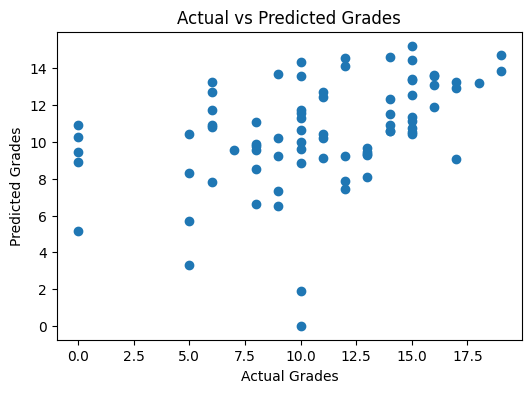

In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades")
plt.show()


## Conclusion

In this project, Linear Regression was used to predict students' final mathematics grades using student-related information. The dataset contained 395 student records. After preprocessing, the data was divided into training and testing sets using an 80:20 ratio.

The model was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score. The model achieved an MAE of 3.44, an RMSE of 4.20, and an R² score of 0.141. These results indicate that the model has limited predictive performance and could be improved by trying other algorithms or selecting more informative features.

This project demonstrates the basic machine learning workflow, including data preprocessing, training, prediction, and model evaluation.